Week 13 – Hotel Booking Demand: Data Cleaning and Preprocessing

1. Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


2. Upload and load the dataset

In [2]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/hotel_bookings.csv")
print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


3. Understand the dataset

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Number of rows: 119390
Number of columns: 32

Column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Last five records:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


4. Standardize column names

In [4]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

print("Standardized column names:")
print(df.columns.tolist())

Standardized column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


5. Identify and handle blank values

In [5]:
# Replace blank strings and whitespace-only values with NaN
df = df.replace(r'^\s*$', np.nan, regex=True)

print("Missing values in each column:")
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
))

Missing values in each column:


,Missing_Count,Missing_Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
hotel,0,0.00
arrival_date_month,0,0.00
arrival_date_week_number,0,0.00
lead_time,0,0.00
is_canceled,0,0.00
stays_in_weekend_nights,0,0.00
stays_in_week_nights,0,0.00


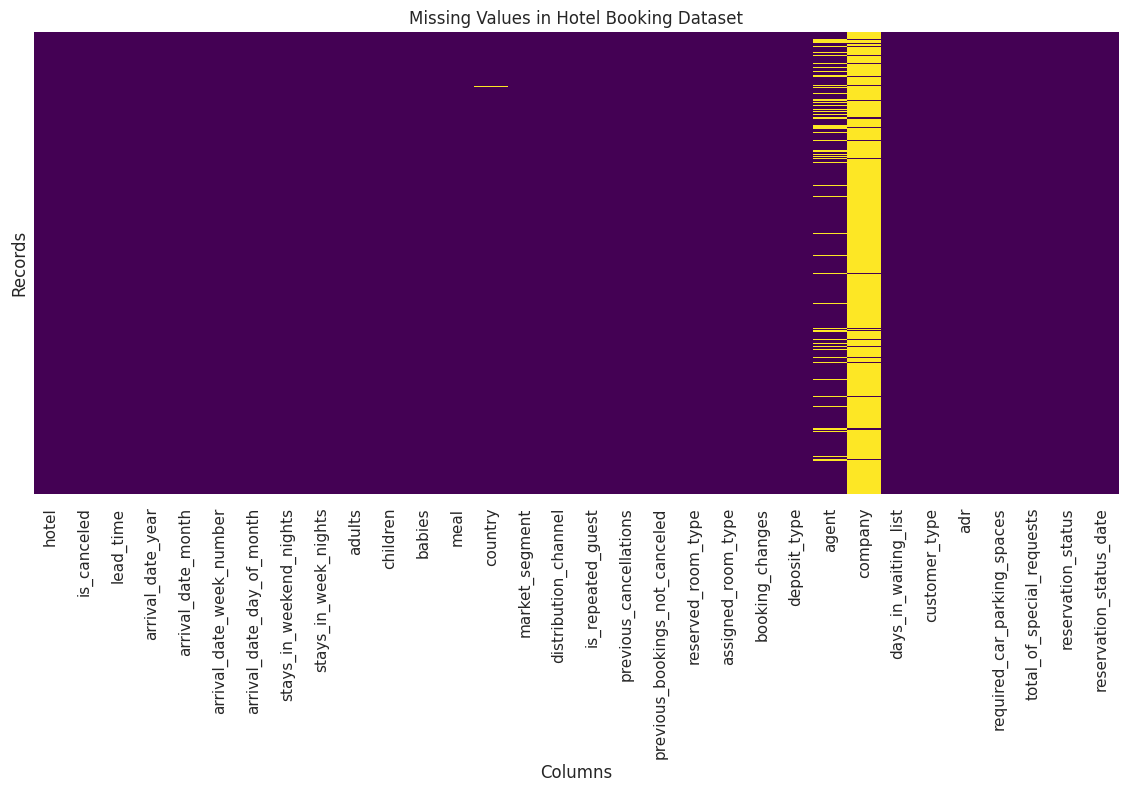

In [6]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Hotel Booking Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.xticks(rotation=90)
plt.show()

6. Check and remove duplicate records

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Number of duplicate rows: 31994
Shape after duplicate removal: (87396, 32)
Remaining duplicates: 0


7. Convert numerical columns into numeric data types

In [8]:
numeric_columns = [
    "is_canceled",
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "agent",
    "company",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numerical columns converted successfully.")
df.info()

Numerical columns converted successfully.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87396 entries, 0 to 87395
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  object 
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  object 
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87392 non-null  float64
 11  babies                          87396 non-null  int

8. Clean categorical columns

In [9]:
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

print("Categorical columns cleaned.")

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))

Categorical columns cleaned.

hotel:
hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: Int64

arrival_date_month:
arrival_date_month
August       11257
July         10057
May           8355
April         7908
June          7765
March         7513
October       6934
September     6690
February      6098
December      5131
Name: count, dtype: Int64

meal:
meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: Int64

country:
country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
IRL     3016
BEL     2081
BRA     1995
NLD     1911
Name: count, dtype: Int64

market_segment:
market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: Int64

distribution_channel:
distribution_channel
TA/TO        69141
Direct       12988


9. Handle missing values carefully

In [10]:
# Children: treat missing values as zero
if "children" in df.columns:
    df["children"] = df["children"].fillna(0)

# Country: retain records with an explicit unknown category
if "country" in df.columns:
    df["country"] = df["country"].fillna("Unknown")

# Identifier columns: do not fabricate agent/company IDs
identifier_columns = ["agent", "company"]

# Fill missing values in other categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in categorical_columns:
    if col not in ["country"]:
        df[col] = df[col].fillna("Unknown")

# Fill missing values in other numerical columns using the median
for col in df.select_dtypes(include=np.number).columns:
    if col not in identifier_columns:
        median_value = df[col].median()

        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)

print("Missing-value treatment completed.")

print("\nRemaining missing values:")
display(df.isnull().sum().sort_values(ascending=False))

Missing-value treatment completed.

Remaining missing values:


,0
company,82137
agent,12193
hotel,0
is_canceled,0
arrival_date_month,0
arrival_date_week_number,0
lead_time,0
arrival_date_year,0
stays_in_week_nights,0
adults,0


10. Validate numerical values

In [11]:
non_negative_columns = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

validation_results = []

for col in non_negative_columns:
    if col in df.columns:
        invalid_count = (df[col] < 0).sum()

        validation_results.append({
            "Column": col,
            "Negative_Values": invalid_count
        })

display(pd.DataFrame(validation_results))

,Column,Negative_Values
0,lead_time,0
1,stays_in_weekend_nights,0
2,stays_in_week_nights,0
3,adults,0
4,children,0
5,babies,0
6,previous_cancellations,0
7,previous_bookings_not_canceled,0
8,booking_changes,0
9,days_in_waiting_list,0


In [12]:
if "adr" in df.columns:
    print("Negative ADR records:", (df["adr"] < 0).sum())
    print("Zero ADR records:", (df["adr"] == 0).sum())
    print("Minimum ADR:", df["adr"].min())
    print("Maximum ADR:", df["adr"].max())

Negative ADR records: 1
Zero ADR records: 1778
Minimum ADR: -6.38
Maximum ADR: 5400.0


In [13]:
invalid_mask = pd.Series(False, index=df.index)

for col in non_negative_columns:
    if col in df.columns:
        invalid_mask |= df[col] < 0

if "adr" in df.columns:
    invalid_mask |= df["adr"] < 0

invalid_records = df[invalid_mask].copy()

print("Invalid records identified:", len(invalid_records))

df = df.loc[~invalid_mask].copy().reset_index(drop=True)

print("Shape after removing invalid negative records:", df.shape)

Invalid records identified: 1
Shape after removing invalid negative records: (87395, 32)


11. Validate booking status and guest information

In [14]:
if "is_canceled" in df.columns:
    print("Cancellation status:")
    display(df["is_canceled"].value_counts(dropna=False))

if "hotel" in df.columns:
    print("\nHotel types:")
    display(df["hotel"].value_counts(dropna=False))

if "customer_type" in df.columns:
    print("\nCustomer types:")
    display(df["customer_type"].value_counts(dropna=False))

if "deposit_type" in df.columns:
    print("\nDeposit types:")
    display(df["deposit_type"].value_counts(dropna=False))

Cancellation status:


,count
is_canceled,
0,63370
1,24025



Hotel types:


,count
hotel,
City Hotel,53428
Resort Hotel,33967



Customer types:


,count
customer_type,
Transient,71986
Transient-Party,11726
Contract,3139
Group,544



Deposit types:


,count
deposit_type,
No Deposit,86250
Non Refund,1038
Refundable,107


In [15]:
guest_columns = ["adults", "children", "babies"]

available_guest_columns = [
    col for col in guest_columns if col in df.columns
]

if available_guest_columns:
    df["total_guests"] = df[available_guest_columns].sum(axis=1)

    df["no_guest_booking"] = df["total_guests"] == 0

    print("Bookings with zero guests:", df["no_guest_booking"].sum())

    display(
        df.loc[df["no_guest_booking"]].head()
    )

Bookings with zero guests: 166


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests,no_guest_booking
2088,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,174.0,0,Transient-Party,0.0,0,0,Check-Out,2015-10-06,0.0,True
2224,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,174.0,0,Transient,0.0,0,0,Check-Out,2015-10-12,0.0,True
2804,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,NaN,0,Transient-Party,0.0,0,0,Check-Out,2015-11-23,0.0,True
3091,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-04,0.0,True
3099,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,NaN,122,Transient-Party,0.0,0,0,Check-Out,2016-01-05,0.0,True


12. Convert arrival date fields into a proper date

In [16]:
required_date_columns = [
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month"
]

if all(col in df.columns for col in required_date_columns):

    month_map = {
        "january": 1,
        "february": 2,
        "march": 3,
        "april": 4,
        "may": 5,
        "june": 6,
        "july": 7,
        "august": 8,
        "september": 9,
        "october": 10,
        "november": 11,
        "december": 12
    }

    month_numeric = (
        df["arrival_date_month"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map(month_map)
    )

    df["arrival_date"] = pd.to_datetime(
        {
            "year": df["arrival_date_year"],
            "month": month_numeric,
            "day": df["arrival_date_day_of_month"]
        },
        errors="coerce"
    )

    print("Arrival date created successfully.")
    display(
        df[required_date_columns + ["arrival_date"]].head()
    )

else:
    print("Required arrival date columns are not all available.")

Arrival date created successfully.


,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


13. Feature engineering

A. Total number of nights

In [17]:
night_columns = [
    "stays_in_weekend_nights",
    "stays_in_week_nights"
]

if all(col in df.columns for col in night_columns):
    df["total_nights"] = (
        df["stays_in_weekend_nights"] +
        df["stays_in_week_nights"]
    )

    print("Total nights feature created.")

Total nights feature created.


B. Total number of guests

In [18]:
available_guest_columns = [
    col for col in ["adults", "children", "babies"]
    if col in df.columns
]

if available_guest_columns:
    df["total_guests"] = df[available_guest_columns].sum(axis=1)

    print("Total guests feature created.")

Total guests feature created.


C. Family booking indicator

In [19]:
if "children" in df.columns and "babies" in df.columns:
    df["is_family"] = (
        (df["children"] > 0) |
        (df["babies"] > 0)
    )

    print("Family booking feature created.")

Family booking feature created.


D. Booking change indicator

In [20]:
if "booking_changes" in df.columns:
    df["has_booking_changes"] = (
        df["booking_changes"] > 0
    )

    print("Booking change feature created.")

Booking change feature created.


E. Special request indicator

In [21]:
if "total_of_special_requests" in df.columns:
    df["has_special_requests"] = (
        df["total_of_special_requests"] > 0
    )

    print("Special request feature created.")

Special request feature created.


F. Arrival year, month, and quarter

In [22]:
if "arrival_date" in df.columns:
    df["arrival_year"] = df["arrival_date"].dt.year
    df["arrival_month"] = df["arrival_date"].dt.month
    df["arrival_month_name"] = df["arrival_date"].dt.month_name()
    df["arrival_quarter"] = (
        "Q" + df["arrival_date"].dt.quarter.astype("string")
    )

    print("Arrival time features created.")

Arrival time features created.


In [23]:
if "arrival_date" in df.columns:
    df["arrival_year"] = df["arrival_date"].dt.year
    df["arrival_month"] = df["arrival_date"].dt.month
    df["arrival_month_name"] = df["arrival_date"].dt.month_name()
    df["arrival_quarter"] = (
        "Q" + df["arrival_date"].dt.quarter.astype("string")
    )

    print("Arrival time features created.")

Arrival time features created.


G. Booking cancellation label

In [24]:
if "is_canceled" in df.columns:
    df["booking_status"] = df["is_canceled"].map({
        0: "Not Canceled",
        1: "Canceled"
    })

    print("Booking status feature created.")

Booking status feature created.


14. Create data quality checks


In [25]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Records",
        "Total Missing Values",
        "Records with Zero Guests"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        df["no_guest_booking"].sum()
            if "no_guest_booking" in df.columns else "Not Available"
    ]
})

display(quality_report)

,Metric,Value
0,Total Records,87395
1,Total Columns,44
2,Duplicate Records,0
3,Total Missing Values,94329
4,Records with Zero Guests,166


15. Descriptive statistical analysis

In [26]:
print("Numerical descriptive statistics:")

display(
    df.describe().T
)

Numerical descriptive statistics:


,count,mean,min,25%,50%,75%,max,std
is_canceled,87395.0,0.274901,0.0,0.0,0.0,1.0,1.0,0.446467
lead_time,87395.0,79.890051,0.0,11.0,49.0,125.0,737.0,86.051937
arrival_date_year,87395.0,2016.210287,2015.0,2016.0,2016.0,2017.0,2017.0,0.686101
arrival_date_week_number,87395.0,26.838526,1.0,16.0,27.0,37.0,53.0,13.674531
arrival_date_day_of_month,87395.0,15.815665,1.0,8.0,16.0,23.0,31.0,8.835121
stays_in_weekend_nights,87395.0,1.005229,0.0,0.0,1.0,2.0,19.0,1.031877
stays_in_week_nights,87395.0,2.625356,0.0,1.0,2.0,4.0,50.0,2.053564
adults,87395.0,1.875794,0.0,2.0,2.0,2.0,55.0,0.626504
children,87395.0,0.138635,0.0,0.0,0.0,0.0,10.0,0.455874
babies,87395.0,0.010824,0.0,0.0,0.0,0.0,10.0,0.113597


In [27]:
categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique values:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(10))


Column: hotel
Unique values: 2


,count
hotel,
City Hotel,53428
Resort Hotel,33967



Column: arrival_date_month
Unique values: 12


,count
arrival_date_month,
August,11257
July,10057
May,8355
April,7908
June,7765
March,7512
October,6934
September,6690
February,6098



Column: meal
Unique values: 5


,count
meal,
BB,67977
SC,9481
HB,9085
Undefined,492
FB,360


... (20 outputs left out)


Column: arrival_quarter
Unique values: 4


,count
arrival_quarter,
Q3,28004
Q2,24028
Q1,18303
Q4,17060



Column: booking_status
Unique values: 2


,count
booking_status,
Not Canceled,63370
Canceled,24025


16. Outlier detection using the IQR method

In [28]:
outlier_columns = [
    "lead_time",
    "adr",
    "total_nights",
    "total_guests",
    "days_in_waiting_list"
]

outlier_results = []

for col in outlier_columns:

    if col in df.columns:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_count = (
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        ).sum()

        outlier_results.append({
            "Column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Outlier_Count": outlier_count
        })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,lead_time,11.0,125.0,114.0,-160.0,296.0,2396
1,adr,72.0,134.0,62.0,-21.0,227.0,2490
2,total_nights,2.0,5.0,3.0,-2.5,9.5,3014
3,total_guests,2.0,2.0,0.0,2.0,2.0,30339
4,days_in_waiting_list,0.0,0.0,0.0,0.0,0.0,860


17. Visualize distributions

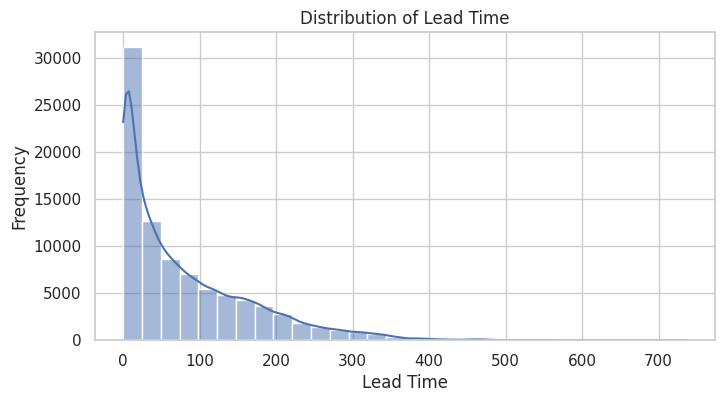

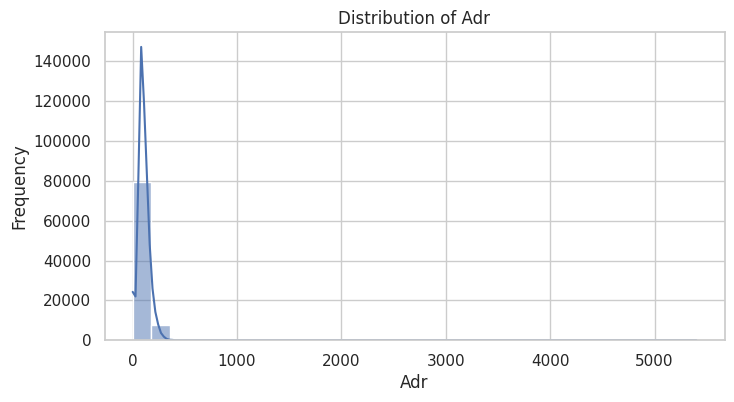

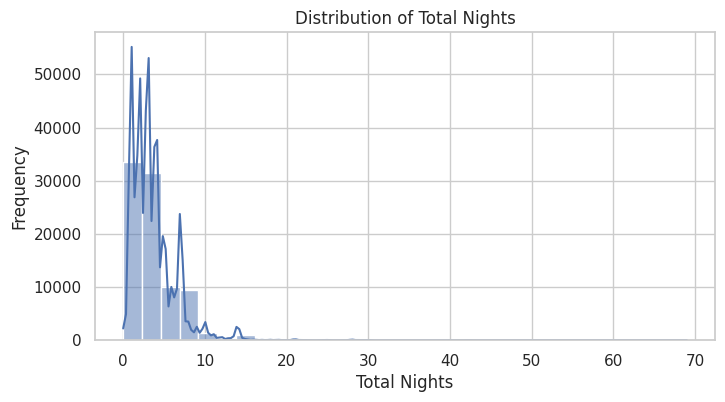

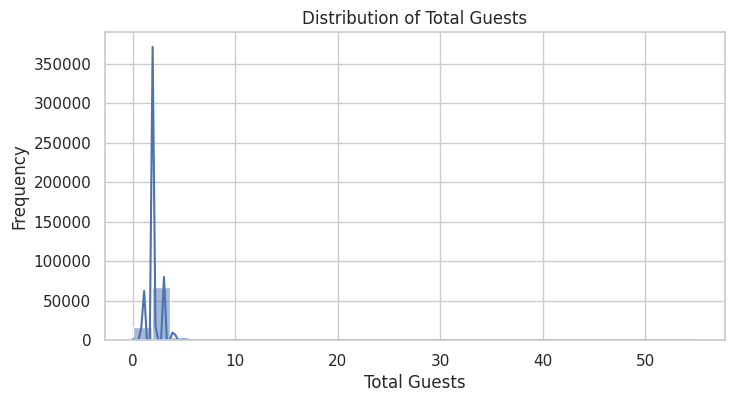

In [29]:
distribution_columns = [
    "lead_time",
    "adr",
    "total_nights",
    "total_guests"
]

available_distribution_columns = [
    col for col in distribution_columns if col in df.columns
]

for col in available_distribution_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Frequency")
    plt.show()

18. Examine hotel and booking categories

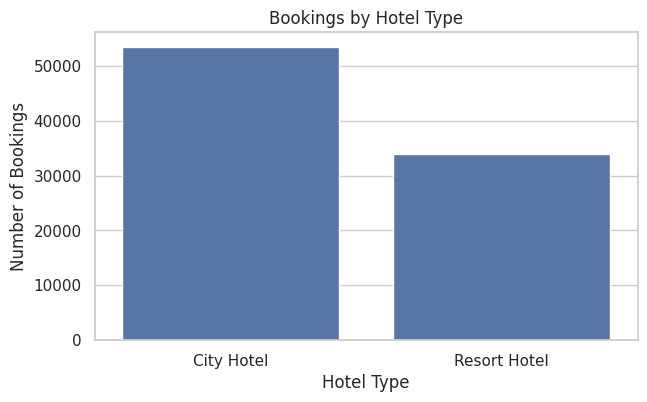

In [30]:
if "hotel" in df.columns:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x="hotel",
        order=df["hotel"].value_counts().index
    )

    plt.title("Bookings by Hotel Type")
    plt.xlabel("Hotel Type")
    plt.ylabel("Number of Bookings")
    plt.show()

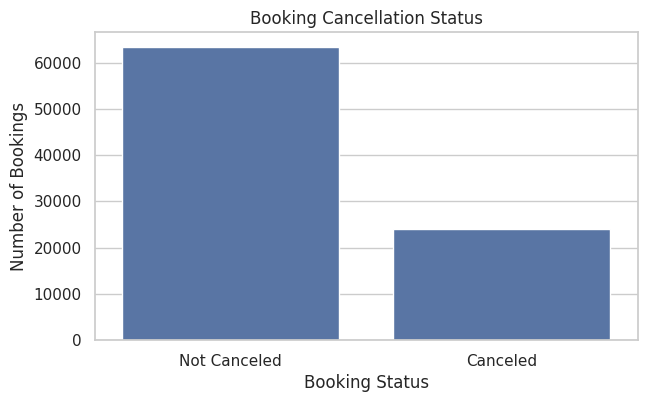

In [31]:
if "booking_status" in df.columns:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x="booking_status",
        order=df["booking_status"].value_counts().index
    )

    plt.title("Booking Cancellation Status")
    plt.xlabel("Booking Status")
    plt.ylabel("Number of Bookings")
    plt.show()

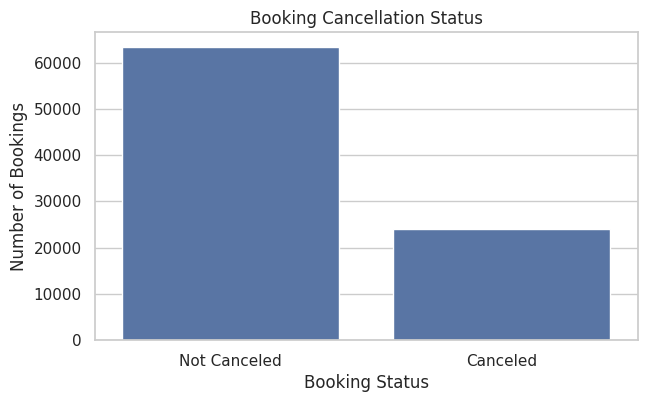

In [32]:
if "booking_status" in df.columns:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x="booking_status",
        order=df["booking_status"].value_counts().index
    )

    plt.title("Booking Cancellation Status")
    plt.xlabel("Booking Status")
    plt.ylabel("Number of Bookings")
    plt.show()

19. Prepare summary reports

In [33]:
# Overall dataset summary
summary_data = {
    "Total_Bookings": len(df),
    "Total_Columns": len(df.columns),
    "Missing_Values": df.isnull().sum().sum(),
    "Duplicate_Records": df.duplicated().sum()
}

if "is_canceled" in df.columns:
    summary_data["Canceled_Bookings"] = (
        df["is_canceled"] == 1
    ).sum()

    summary_data["Not_Canceled_Bookings"] = (
        df["is_canceled"] == 0
    ).sum()

if "total_nights" in df.columns:
    summary_data["Average_Nights"] = df["total_nights"].mean()

if "total_guests" in df.columns:
    summary_data["Average_Guests"] = df["total_guests"].mean()

if "adr" in df.columns:
    summary_data["Average_ADR"] = df["adr"].mean()

overall_summary = pd.DataFrame(
    [summary_data]
)

display(overall_summary)

,Total_Bookings,Total_Columns,Missing_Values,Duplicate_Records,Canceled_Bookings,Not_Canceled_Bookings,Average_Nights,Average_Guests,Average_ADR
0,87395,44,94329,0,24025,63370,3.630585,2.025253,106.338536


In [34]:
if "hotel" in df.columns:

    hotel_summary = df.groupby("hotel").agg(
        total_bookings=("hotel", "count")
    ).reset_index()

    if "adr" in df.columns:
        adr_summary = df.groupby("hotel")["adr"].mean().reset_index()
        adr_summary.columns = ["hotel", "average_adr"]

        hotel_summary = hotel_summary.merge(
            adr_summary,
            on="hotel",
            how="left"
        )

    if "total_nights" in df.columns:
        nights_summary = (
            df.groupby("hotel")["total_nights"]
            .mean()
            .reset_index()
        )

        nights_summary.columns = [
            "hotel",
            "average_total_nights"
        ]

        hotel_summary = hotel_summary.merge(
            nights_summary,
            on="hotel",
            how="left"
        )

    display(hotel_summary)

,hotel,total_bookings,average_adr,average_total_nights
0,City Hotel,53428,110.985944,3.146609
1,Resort Hotel,33967,99.028449,4.391851


20. Export cleaned dataset and reports

In [35]:
output_folder = "Week_13_Hotel_Booking_Reports"

os.makedirs(output_folder, exist_ok=True)

# Export cleaned dataset
df.to_csv(
    os.path.join(output_folder, "hotel_bookings_cleaned.csv"),
    index=False
)

# Export missing value summary
missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

missing_summary.to_csv(
    os.path.join(output_folder, "missing_value_summary.csv"),
    index=False
)

# Export duplicate summary
duplicate_summary = pd.DataFrame({
    "Metric": ["Remaining Duplicate Records"],
    "Count": [df.duplicated().sum()]
})

duplicate_summary.to_csv(
    os.path.join(output_folder, "duplicate_summary.csv"),
    index=False
)

# Export invalid records identified before removal
invalid_records.to_csv(
    os.path.join(output_folder, "invalid_records_removed.csv"),
    index=False
)

# Export outlier summary
outlier_summary.to_csv(
    os.path.join(output_folder, "outlier_summary.csv"),
    index=False
)

# Export overall summary
overall_summary.to_csv(
    os.path.join(output_folder, "hotel_booking_summary.csv"),
    index=False
)

# Export hotel-wise summary if generated
if "hotel" in df.columns:
    hotel_summary.to_csv(
        os.path.join(output_folder, "hotel_wise_summary.csv"),
        index=False
    )

print("All reports exported successfully.")

All reports exported successfully.


21. Final validation

In [36]:
print("FINAL DATASET VALIDATION")
print("=" * 50)

print("Final shape:", df.shape)

print("\nRemaining missing values:")
display(
    df.isnull().sum().sort_values(ascending=False).head(15)
)

print("\nRemaining duplicate records:", df.duplicated().sum())

print("\nFinal data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFinal dataset preview:")
display(df.head())

print("\nWeek 13 preprocessing completed successfully.")

FINAL DATASET VALIDATION
Final shape: (87395, 44)

Remaining missing values:


,0
company,82136
agent,12193
hotel,0
is_canceled,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0



Remaining duplicate records: 0

Final data types:


,Data Type
hotel,string[python]
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,string[python]
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64



Final dataset preview:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,arrival_date,total_nights,is_family,has_booking_changes,has_special_requests,arrival_year,arrival_month,arrival_month_name,arrival_quarter,booking_status
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,2015-07-01,0,False,True,False,2015,7,July,Q3,Not Canceled
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,2015-07-01,0,False,True,False,2015,7,July,Q3,Not Canceled
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,2015-07-01,1,False,False,False,2015,7,July,Q3,Not Canceled
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,2015-07-01,1,False,False,False,2015,7,July,Q3,Not Canceled
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,2015-07-01,2,False,False,True,2015,7,July,Q3,Not Canceled



Week 13 preprocessing completed successfully.
